In [ ]:
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
import cartopy
from cartopy.io import shapereader
import cartopy.crs as ccrs
import geopandas
import numpy as np
from datetime import datetime, timedelta
import os
from tqdm.notebook import tqdm
from matplotlib.patches import Rectangle

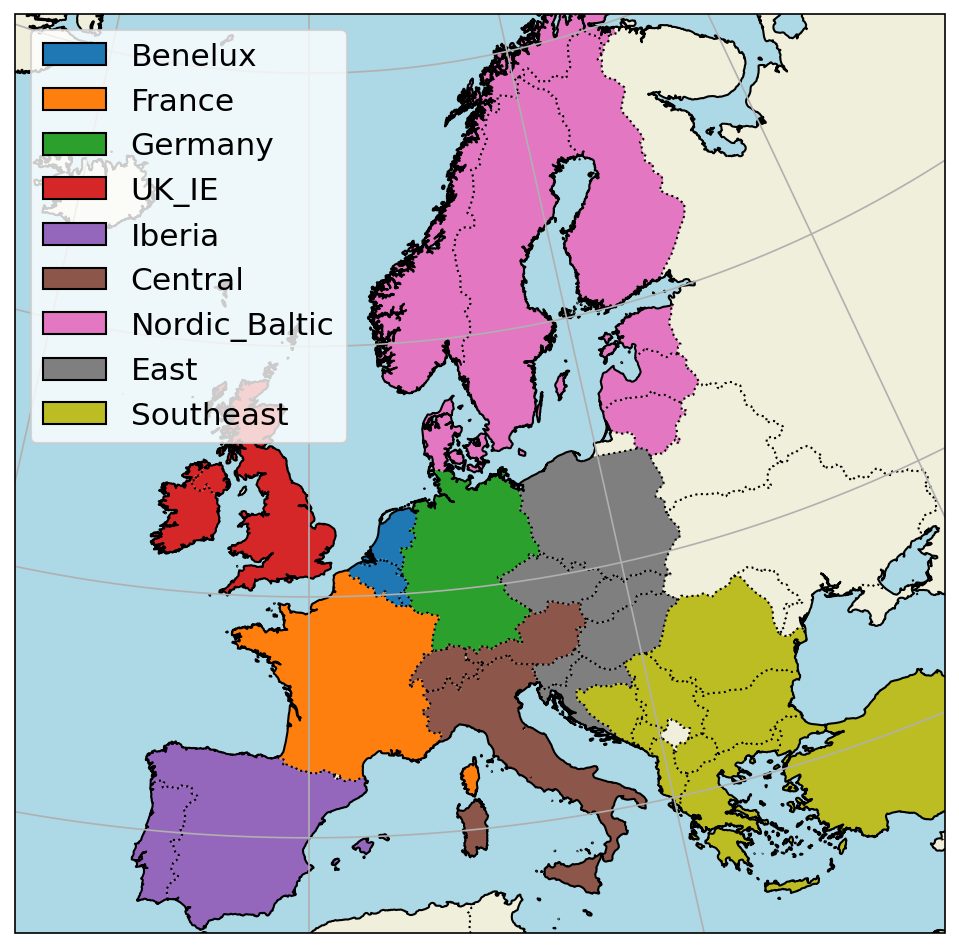

In [8]:
resolution = "10m"
category = "cultural"
name = "admin_0_countries"
shpfilename = shapereader.natural_earth(resolution, category, name)

# read the shapefile using geopandas
df = geopandas.read_file(shpfilename)

# Set up the canvas
fig = plt.figure(figsize=(8, 8), dpi=150)
central_lon, central_lat = 0, 52
extent = [-15, 33, 35, 70]
# ax = plt.axes(projection=cartopy.crs.EuroPP())
ax = plt.axes(
    projection=cartopy.crs.LambertConformal(
        central_longitude=central_lon, central_latitude=central_lat
    )
)
ax.set_extent(extent)
ax.gridlines()

# Add natural earth features and borders
ax.add_feature(cartopy.feature.BORDERS, linestyle=":", alpha=1)
ax.add_feature(cartopy.feature.OCEAN, facecolor=("lightblue"))
ax.add_feature(cartopy.feature.LAND)
ax.coastlines(resolution="10m")

# Insert your lists of countries and lag times here

# countries = [
#     "AUT",
#     "BEL",
#     "CHE",
#     "CZE",
#     "DEU",
#     "DNK",
#     "ESP",
#     "EST",
#     "FIN",
#     "FRA",
#     "GBR",
#     "HRV",
#     "HUN",
#     "IRL",
#     "ITA",
#     "LTU",
#     "LVA",
#     "NLD",
#     "NOR",
#     "POL",
#     "PRT",
#     "SVK",
#     "SVN",
#     "SWE",
# ]

# regions = {
#     "Northern": ["FIN", "NOR", "SWE"],
#     "Baltic": ["EST", "LTU", "LVA"],
#     "Northwestern": ["BEL", "DEU", "GBR", "NLD", "IRL", "DNK"],
#     "Central": ["ITA", "AUT", "CHE", "FRA"],
#     "Eastern": ["POL", "HRV", "HUN", "CZE", "SVK", "SVN"],
#     "Iberia": ["ESP", "PRT"],
# }

regions = {
    "Benelux": ["NL", "BE", "LU"],
    "France": ["FR"],
    "Germany": ["DE"],
    "UK_IE": ["GB", "IE"],
    "Iberia": ["ES", "PT"],
    "Central": ["AT", "CH", "IT", "MT"],
    "Nordic_Baltic": ["EE", "LV", "LT", "NO", "SE", "FI", "DK"],
    "East": ["PL", "CZ", "SK", "HU", "HR", "SI"],
    "Southeast": ["BA", "RS", "RO", "MK", "AL", "ME", "BG", "TR", "GR"],
}


region_colors = {
    "Benelux": "C0",
    "France": "C1",
    "Germany": "C2",
    "UK_IE": "C3",
    "Iberia": "C4",
    "Central": "C5",
    "Nordic_Baltic": "C6",
    "East": "C7",
    "Southeast": "C8",
}

legend_handles = []


from matplotlib.patches import Rectangle

for region, countries_list in regions.items():
    region_color = region_colors[region]

    for country in countries_list:
        poly = df.loc[df["ISO_A2_EH"] == country]["geometry"].values[0]
        ax.add_geometries(
            poly,
            crs=ccrs.PlateCarree(),
            facecolor=region_color,
            edgecolor="none",
            zorder=1,
        )

    legend_handles.append(
        Rectangle((0, 0), 1, 1, facecolor=region_color, edgecolor="black")
    )
    ax.legend(
        legend_handles, regions.keys(), loc="upper left", fontsize=15
    )  # , bbox_to_anchor=(1, 1), fontsize = 15)

In [5]:
country

'UK'